# Question 3

## Question 3.1: DataFrame Generation

In [3]:
# Importing the necessary libraries
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer

# Importing the os library to work with file paths
import os

# 3.1 Loading the research documents
# Defining the directory containing the research corpus
corpus_path = "/Users/oratilwephage/Documents/Honours/Natural Language Processing with Python (ITNPA4-T34)/Project /Project 1 Required Resources-20261104/research_corpus"

# Creating an empty dictionary to store the document names and their content
documents = {}

# Looping through the five research documents
for i in range(1, 6):

    # Creating the filename
    filename = f"research_{i}.txt"

    # Creating the full file path
    filepath = os.path.join(corpus_path, filename)

    # Opening and reading the text file
    with open(filepath, "r", encoding="utf-8") as file:
        content = file.read()

    # Storing the document name and its text content
    documents[filename] = content

# 3.1 The DataFrame Generation
# Converting the dictionary into a DataFrame
df = pd.DataFrame(
    list(documents.items()),
    columns=["Article_ID", "Content"]
)

# Displaying the generated DataFrame
print("3.1 DATAFRAME GENERATION ")
print(df.head())

# Displaying the number of documents loaded
print("\nTotal documents loaded:", len(df))

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.
3.1 DATAFRAME GENERATION 
       Article_ID                                            Content
0  research_1.txt  The purposes of this article are to position m...
1  research_2.txt  Now I see it, now I don’t:\nresearcher’s posit...
2  research_3.txt  DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3  research_4.txt  Abstract\nCronbach’s alpha is a statistic comm...
4  research_5.txt  Denzin’s Paradigm Shift: Revisiting Triangulat...

Total documents loaded: 5


## Question 3.2: Text Preprocessing (Denoising Pipeline)

In [4]:
# 3.2 The preprocessing function 

# Defining a function to clean and preprocess text
def preprocess_text(text):

    # Converting all text to lowercase
    text = text.lower()

    # Removing punctuation, numbers and special characters
    text = re.sub(r'[^a-z\s]', '', text)

    # Splitting the text into individual words
    words = text.split()

    # Defining a basic set of English stopwords
    stopwords = set([
        "the", "a", "an", "and", "or", "in", "of", "to", "is",
        "was", "for", "on", "with", "as", "by", "at", "this",
        "that", "these", "those", "are", "it", "its", "be",
        "from", "have", "has", "had", "which", "also", "were",
        "been", "their", "our", "we", "they", "i"
    ])

    # Removing stopwords and short words
    cleaned_words = [
        word for word in words
        if word not in stopwords and len(word) > 2
    ]

    # Returning the cleaned text
    return " ".join(cleaned_words)


# Applying the preprocessing function to the DataFrame
df['Cleaned_Content'] = df['Content'].apply(preprocess_text)

# Displaying the preprocessed data
print("3.2 PREPROCESSED DATA")
print(df[['Article_ID', 'Cleaned_Content']].head(2))

3.2 PREPROCESSED DATA
       Article_ID                                    Cleaned_Content
0  research_1.txt  purposes article position mixed methods resear...
1  research_2.txt  now see now dont researchers position reflexiv...


## Question 3.3: First Article Summarization & Keyword Visualization

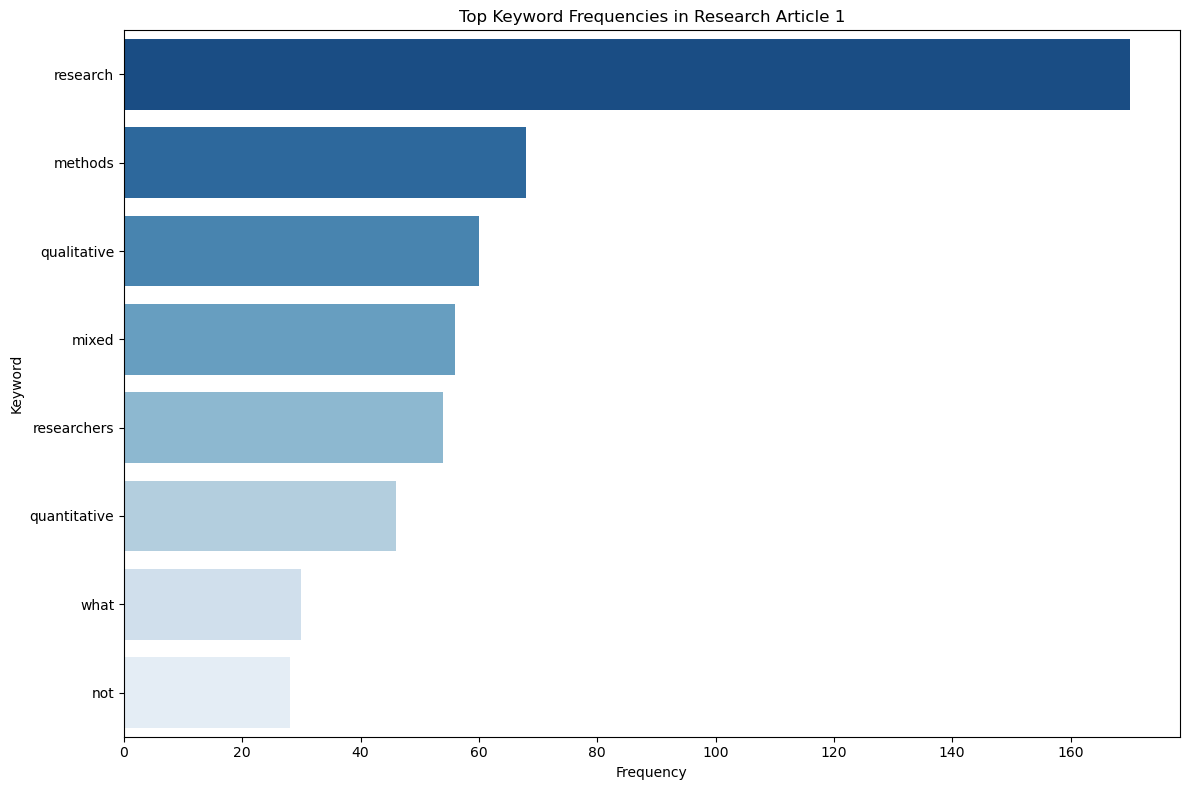

In [5]:
# 3.3 The Frequency-based summarisation of Article 1
# Importing Counter to calculate word frequencies
from collections import Counter

# Defining a function for frequency-based summarisation
def get_freq_summary(original_text, cleaned_text, top_n=3):

    # Calculating the frequency of cleaned words
    freq = Counter(cleaned_text.split())

    # Splitting the original article into sentences
    sentences = re.split(r'(?<=[.!?])\s+', original_text.strip())

    # Creating an empty dictionary for sentence scores
    sent_scores = {}

    # Scoring each sentence according to keyword frequencies
    for sent in sentences:

        # Preprocessing each sentence for consistent matching
        cleaned_sent = preprocess_text(sent)

        # Calculating the sentence score
        score = sum(
            freq[word]
            for word in cleaned_sent.split()
            if word in freq
        )

        # Storing sentences with their scores
        if score > 0:
            sent_scores[sent] = score

    # Sorting sentences by score in descending order
    sorted_sents = sorted(
        sent_scores.items(),
        key=lambda x: x[1],
        reverse=True
    )

    # Selecting the highest-scoring sentences
    selected_sentences = sorted_sents[:top_n]

    # Restoring the original sentence order for readability
    selected_sentences = sorted(
        selected_sentences,
        key=lambda x: sentences.index(x[0])
    )

    # Creating the final summary
    summary = " ".join(sentence for sentence, score in selected_sentences)

    # Returning the summary and word frequencies
    return summary, freq


# Extracting the original and cleaned content of Article 1
original_article_1 = df.loc[0, 'Content']
cleaned_article_1 = df.loc[0, 'Cleaned_Content']

# Generating the summary and keyword frequencies
article_1_summary, art1_freq = get_freq_summary(
    original_article_1,
    cleaned_article_1,
    top_n=3
)

# Extracting the top 8 most frequent keywords
top_art1_words = art1_freq.most_common(8)

# Separating keywords and their frequencies
words_art1 = [word for word, count in top_art1_words]
counts_art1 = [count for word, count in top_art1_words]


# Plotting the top keyword frequencies for Article 1

plt.figure(figsize=(12, 8))

# Creating a horizontal bar chart
sns.barplot(
    x=counts_art1,
    y=words_art1,
    hue=words_art1,
    palette='Blues_r',
    legend=False
)

# Adding chart labels and title
plt.title('Top Keyword Frequencies in Research Article 1')
plt.xlabel('Frequency')
plt.ylabel('Keyword')

# Adjusting layout to prevent overlapping
plt.tight_layout()

# Saving the figure to a PNG file
plt.savefig('article_1_keywords.png', dpi=300, bbox_inches='tight')

# Displaying the plot in Jupyter Notebook
plt.show()

## Question 3.4: Aggregate Summarization & Visualization for Remaining Corpus (research_2.txt to research_5.txt)

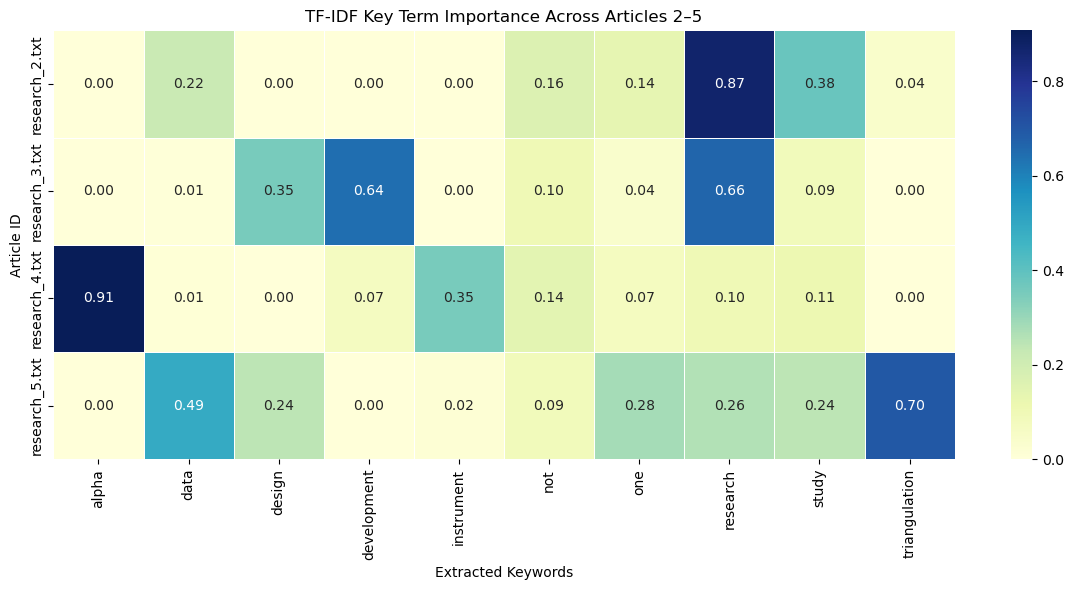

-------------------------
3.3 SUMMARY OF ARTICLE 1
The purposes of this article are to position mixed methods research
(mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism
as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting
mixed methods research. In doing this, we briefly review the paradigm “wars” and incompatibility thesis, we show some commonalities between quantitative and qualitative research, we explain the
tenets of pragmatism, we explain the fundamental principle of mixed
research and how to apply it, we provide specific sets of designs for
the two major types of mixed methods research (mixed-model designs and mixed-method designs), and, finally, we explain mixed methods research as following (recursively) an eight-step process. Our purpose in writing this article is to present mixed methods research as the third researc

In [6]:
# 3.4 The TF-IDF Corpus summarisation for articles 2-5

# Selecting the cleaned content of Articles 2 to 5
remaining_docs = df['Cleaned_Content'].iloc[1:].tolist()

# Selecting the article identifiers
remaining_ids = df['Article_ID'].iloc[1:].tolist()


# TF-IDF Vectorisation

# Creating a TF-IDF vectorizer
# max_features=10 extracts up to 10 important terms
vectorizer = TfidfVectorizer(max_features=10)

# Transforming the remaining documents into TF-IDF features
tfidf_matrix = vectorizer.fit_transform(remaining_docs)

# Extracting the feature names
feature_names = vectorizer.get_feature_names_out()

# Creating a DataFrame containing the TF-IDF scores
tfidf_df = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=feature_names,
    index=remaining_ids
)


# Plotting the TF-IDF heatmap

plt.figure(figsize=(12, 6))

# Creating the heatmap
sns.heatmap(
    tfidf_df,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5,
    cbar=True
)

# Adding chart labels and title
plt.title('TF-IDF Key Term Importance Across Articles 2–5')
plt.xlabel('Extracted Keywords')
plt.ylabel('Article ID')

# Adjusting the layout
plt.tight_layout()

# Saving the heatmap
plt.savefig('remaining_corpus_tfidf.png', dpi=300, bbox_inches='tight')

# Displaying the heatmap in Jupyter Notebook
plt.show()


# Displaying the results 

# Displaying the frequency-based summary of Article 1
print("-------------------------")
print("3.3 SUMMARY OF ARTICLE 1")
print(article_1_summary)


# Displaying the keyword frequencies of Article 1
print("TOP KEYWORD FREQUENCIES: ARTICLE 1")
print(pd.DataFrame(
    top_art1_words,
    columns=['Keyword', 'Frequency']
))


# Displaying the TF-IDF results for Articles 2–5
print("------------------------------------------")
print("3.4 TF-IDF SUMMARY FOR REMAINING ARTICLES")
print(tfidf_df.round(3))

# Question 4

## Question 4.1: LDA Topic Modeling & Visualization

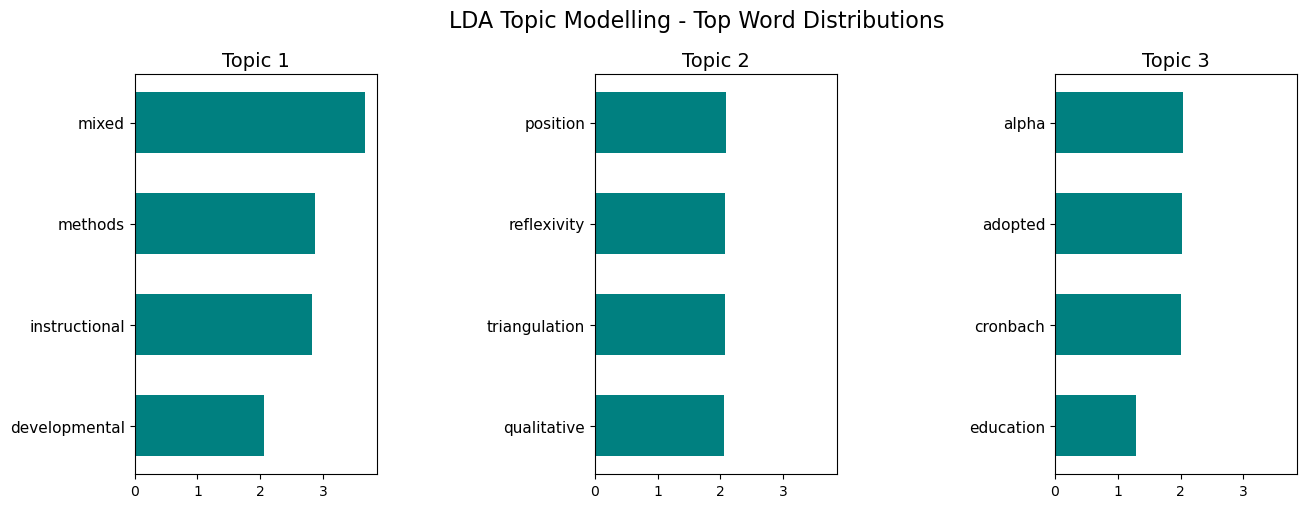

In [7]:
#Importing the necessary libraries
import matplotlib.pyplot as plt
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer

# Sampling the preprocessed corpus (Articles 1-5)
corpus = [
    (
        "purposes article position mixed methods research mixed research"
        " synonym natural complement traditional qualitative quantitative"
        " research present pragmatism offering attractive philosophical"
        " partner mixed methods research provide framework designing"
        " conducting mixed methods research"
    ),
    (
        "now see now dont researchers position reflexivity qualitative"
        " research article addresses potential effects reflexivity"
        " researchers social position gender age race immigration status"
        " sexual orientation personal experiences political professional"
        " beliefs"
    ),
    (
        "developmental research studies instructional design development field"
        " instructional technology has traditionally involved unique blend"
        " theory practice blend most obvious developmental research those"
        " studies that involve production knowledge ultimate aim improving"
        " processes instructional design development evaluation"
    ),
    (
        "cronbach alpha statistic commonly quoted authors demonstrate that"
        " tests scales that have been constructed adopted research projects"
        " fit purpose cronbach alpha regularly adopted studies science"
        " education usually measure reliability"
    ),
    (
        "denzin paradigm shift revisiting triangulation qualitative research"
        " one approach promote social change mitigate bias enhance reaching"
        " data saturation through triangulation multiple sources data"
    ),
]

# 1. Vectorising the text using CountVectorizer (required for LDA)
tf_vectorizer = CountVectorizer(max_df=0.95, min_df=1, stop_words="english")
tf = tf_vectorizer.fit_transform(corpus)
tf_feature_names = tf_vectorizer.get_feature_names_out()

# 2. Fitting the  LDA model (e.g., 3 topics)
n_topics = 3
lda = LatentDirichletAllocation(
    n_components=n_topics, max_iter=10, learning_method="online", random_state=42
)
lda.fit(tf)


# 3. Using the helper function to plot top words per topic
def plot_top_words(model, feature_names, n_top_words, title):
  fig, axes = plt.subplots(1, n_topics, figsize=(15, 5), sharex=True)
  for topic_idx, ax in enumerate(axes):
    top_features_ind = model.components_[topic_idx].argsort()[: -n_top_words - 1 : -1]
    top_features = [feature_names[i] for i in top_features_ind]
    weights = model.components_[topic_idx][top_features_ind]

    ax.barh(top_features, weights, height=0.6, color="teal")
    ax.set_title(f"Topic {topic_idx + 1}", fontdict={"fontsize": 14})
    ax.invert_yaxis()
    ax.tick_params(axis="both", which="both", labelsize=11)
    for tick in ax.xaxis.get_major_ticks():
      tick.label1.set_fontsize(10)
  plt.suptitle(title, fontsize=16)
  plt.subplots_adjust(top=0.85, bottom=0.05, wspace=0.9)
  plt.show()


# Displaying the distribution plot
plot_top_words(
    lda, tf_feature_names, 4, "LDA Topic Modelling - Top Word Distributions"
)

## Question 4.2: Interactive PyLDAvis Intertopic Distance Map

In [8]:
%pip install --upgrade pyLDAvis

/opt/anaconda3/lib/python3.13/pty.py:95: DeprecationWarning: This process (pid=19909) is multi-threaded, use of forkpty() may lead to deadlocks in the child.
  pid, fd = os.forkpty()


Note: you may need to restart the kernel to use updated packages.


In [10]:
# Importing the necessary libraries
import gensim
import gensim.corpora as corpora
from gensim.models import LdaModel
import pyLDAvis
import pyLDAvis.gensim_models

# Tokenising the corpus for Gensim
tokenized_corpus = [doc.split() for doc in corpus]

# Creating the  Dictionary and Corpus ID mappings
id2word = corpora.Dictionary(tokenized_corpus)
gensim_corpus = [id2word.doc2bow(text) for text in tokenized_corpus]

# Training the Gensim LDA Model
lda_gensim = LdaModel(
    corpus=gensim_corpus,
    id2word=id2word,
    num_topics=3,
    random_state=100,
    update_every=1,
    chunksize=10,
    passes=10,
    alpha="auto",
    per_word_topics=True,
)

# Preparing the PyLDAvis visualization dashboard
pyLDAvis.enable_notebook()
vis_data = pyLDAvis.gensim_models.prepare(
    lda_gensim, gensim_corpus, id2word, sort_topics=False
)

# Displaying the  interactive map in notebook or save as standalone HTML
pyLDAvis.save_html(vis_data, "lda_interactive_visualization.html")
print("Interactive LDA visualization saved to 'lda_interactive_visualization.html'.")

Interactive LDA visualization saved to 'lda_interactive_visualization.html'.


## Saving the HTML to my Documents folder

In [11]:
# Importing the necessary libraries
import os
import pyLDAvis
import pyLDAvis.gensim_models

# Step 1: Preparing the interactive LDA visualisation
vis_data = pyLDAvis.gensim_models.prepare(
    lda_gensim,
    gensim_corpus,
    id2word,
    sort_topics=False
)

# Step 2: Defining the folder where the HTML file should be saved
save_path = "/Users/oratilwephage/Documents/Honours/Natural Language Processing with Python (ITNPA4-T34)/Project /Project 1 Required Resources-20261104"

# Step 3: Creating the folder if it does not already exist
os.makedirs(save_path, exist_ok=True)

# Step 4: Creating the full file path
html_path = os.path.join(save_path, "index.html")

# Step 5: Saving the interactive LDA visualisation
pyLDAvis.save_html(vis_data, html_path)

# Step 6: Confirming successful saving
print("HTML file saved successfully!")
print("Location:", html_path)

HTML file saved successfully!
Location: /Users/oratilwephage/Documents/Honours/Natural Language Processing with Python (ITNPA4-T34)/Project /Project 1 Required Resources-20261104/index.html
